In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
df = pd.read_csv ("/content/insurance.csv")
df

,age,sex,bmi,children,smoker,region,expenses
0,19,female,27.9,0,yes,southwest,16884.92
1,18,male,33.8,1,no,southeast,1725.55
2,28,male,33.0,3,no,southeast,4449.46
3,33,male,22.7,0,no,northwest,21984.47
4,32,male,28.9,0,no,northwest,3866.86
...,...,...,...,...,...,...,...
1333,50,male,31.0,3,no,northwest,10600.55
1334,18,female,31.9,0,no,northeast,2205.98
1335,18,female,36.9,0,no,southeast,1629.83
1336,21,female,25.8,0,no,southwest,2007.95


In [3]:

df = pd.read_csv("/content/insurance.csv")
for col in ['sex', 'smoker', 'region']:
    df[col] = df[col].astype(str).str.strip().str.lower()

df['smoker'] = df['smoker'].map({'yes': 1, 'no': 0})
df['region'] = df['region'].map({'northwest': 1, 'northeast': 2,
                                 'southeast': 3, 'southwest': 4})
df['sex'] = df['sex'].map({'female': 1, 'male': 0})

print(df.isnull().sum())

x = df.drop('expenses', axis=1).values.astype(float)
y = df['expenses'].values.astype(float)

print("x shape:", x.shape)
print("x dtype:", x.dtype)


age         0
sex         0
bmi         0
children    0
smoker      0
region      0
expenses    0
dtype: int64
x shape: (1338, 6)
x dtype: float64


In [4]:
#put indices into an array, randomly shuffle them, split into 80-20, assign array of training indices (first 80%), assign array of testing indices (last 20%), create 4 new arrays for x and y training and testing sets
np.random.seed(42)
index = np.random.permutation(len(x))
split = int (0.8*(len(x)))
train = index [:split]
test = index [split:]
x_train = x[train]                    #training set
x_test = x[test]                      #testing set
y_train = y[train]
y_test = y[test]


In [5]:
# Normalize features (zero mean, unit variance)
x_mean = x_train.mean(axis=0)
x_std  = x_train.std(axis=0)

x_trains = (x_train - x_mean) / x_std
x_tests  = (x_test  - x_mean) / x_std  # use training stats on test set!

In [6]:
print ("Shape of training set x: ", x_trains.shape)
print ("Shape of testing set x: ", x_tests.shape)
print ("Shape of training set y: ", y_train.shape)
print ("Shape of testing set y: ", y_test.shape)

Shape of training set x:  (1070, 6)
Shape of testing set x:  (268, 6)
Shape of training set y:  (1070,)
Shape of testing set y:  (268,)


In [7]:
#initial values of w and b
b_init = 0
w_init = np.array([0,0,0,0,0,0])
print (w_init.shape)
w_init

(6,)


array([0, 0, 0, 0, 0, 0])

In [8]:
#find values of f for each point with initial w and b
def predict(x, w, b):
    p = np.dot(x, w) + b
    return p

In [9]:
# get a row from our training data
x_vec = x_trains[0,:]

# make a prediction
f_wb = predict(x_vec,w_init, b_init)
print(f"f prediction: {f_wb}")


f prediction: 0.0


In [10]:
#compute cost for individual values of x
def compute_cost(x, y, w, b):
    m = x.shape[0]
    cost = 0.0
    for i in range(m):
        f_wb_i = np.dot(x[i], w) + b
        cost = cost + (f_wb_i - y[i])**2
    cost = cost / (2 * m)
    return cost

cost = compute_cost(x_trains, y_train, w_init, b_init)


In [11]:
#gradient calculation for each point
def compute_gradient(x, y, w, b):

    m,n = x.shape
    dj_dw = np.zeros((n,))
    dj_db = 0.0

    for i in range(m):
        err = (np.dot(x[i], w) + b) - y[i]
        for j in range(n):
            dj_dw[j] += err * x[i, j]
        dj_db = dj_db + err
    dj_dw = dj_dw / m
    dj_db = dj_db / m

    return dj_db, dj_dw

In [12]:
#gradient descent
def gradient_descent (x,y,w,b,cost_function,gradient_function,alpha,iterations):
  J = []
  for i in range(iterations):
    dj_db, dj_dw = gradient_function(x,y,w,b)
    w = w-alpha*(dj_dw)
    b = b-alpha*(dj_db)
    cost = cost_function(x,y,w,b)
    J.append(cost)
    if i%100 == 0:
      print ("Cost at iteration ", i, " = ", cost)
  return w,b,J


In [14]:
iterations = 1000
alpha = 0.01
# run gradient descent
w_final, b_final, J = gradient_descent(x_trains, y_train, w_init, b_init,
                                                    compute_cost, compute_gradient,
                                                    alpha, iterations)
print(f"b,w found by gradient descent: {b_final:0.2f},{w_final} ")
#for i in range(m):
    #print(f"prediction: {np.dot(X_train[i], w_final) + b_final:0.2f}, target value: {y_train[i]}")

Cost at iteration  0  =  157867481.54532534
Cost at iteration  100  =  36882418.61642214
Cost at iteration  200  =  20611676.082600854
Cost at iteration  300  =  18390613.163140986
Cost at iteration  400  =  18083452.119100682
Cost at iteration  500  =  18040475.56616953
Cost at iteration  600  =  18034397.574919615
Cost at iteration  700  =  18033529.1953901
Cost at iteration  800  =  18033403.892858826
Cost at iteration  900  =  18033385.63343359
b,w found by gradient descent: 13314.14,[3649.31072558   25.20469457 1932.75547238  581.23153563 9559.38287869
 -311.73412737] 


In [15]:
y_pred = predict(x_tests, w_final, b_final)

mae = np.mean(np.abs(y_pred - y_test))
ss_res = np.sum((y_test - y_pred) ** 2)
ss_tot = np.sum((y_test - y_test.mean()) ** 2)
r2 = 1 - ss_res / ss_tot

print(f"Test R²: {r2:.2f}")
print(f"Test MAE: ${mae:,.0f}")

Test R²: 0.75
Test MAE: $4,058


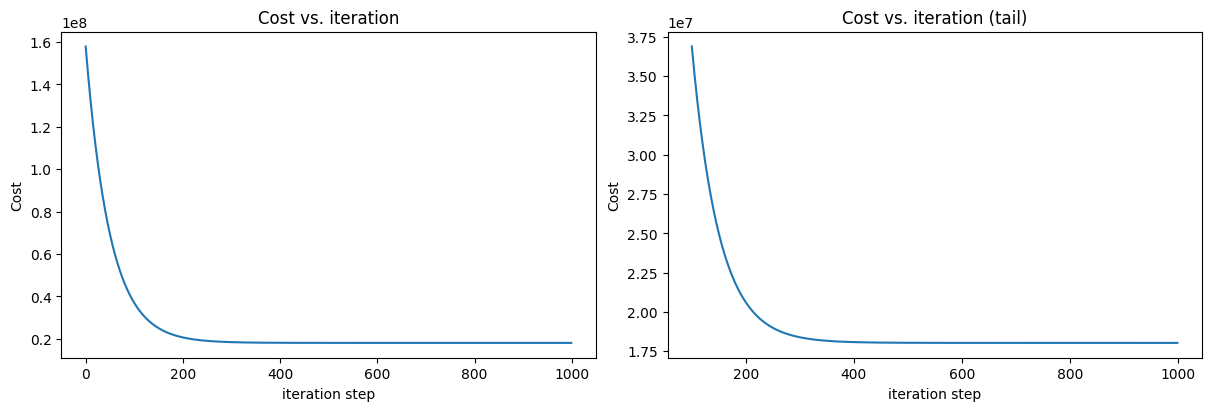

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, constrained_layout=True, figsize=(12, 4))
ax1.plot(J)
ax2.plot(100 + np.arange(len(J[100:])), J[100:])
ax1.set_title("Cost vs. iteration");  ax2.set_title("Cost vs. iteration (tail)")
ax1.set_ylabel('Cost')             ;  ax2.set_ylabel('Cost')
ax1.set_xlabel('iteration step')   ;  ax2.set_xlabel('iteration step')
plt.show()